# Palangka Raya AOI and Sentinel-1 composites

Plots the AOI on a basemap and the Sentinel-1 RTC composites (Earthdata, 30 m, ascending) as RGB: R = VV, G = VH, B = (VV - VH) / (VV + VH).

In [1]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

AOI_PATH = "input/palangka_raya.geojson"
S1_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026/s1"
S1_DATES = ["2026-06", "2026-10"]

## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="white", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Load AOI

In [3]:
aoi = gpd.read_file(AOI_PATH).to_crs("EPSG:4326")
print(aoi.crs, aoi.total_bounds)
aoi

EPSG:4326 [113.55933468  -2.58318144 114.21626255  -1.90399978]


,geometry
0,"POLYGON ((113.55935 -1.904, 114.21624 -1.904, ..."


## 2. Plot AOI with basemap

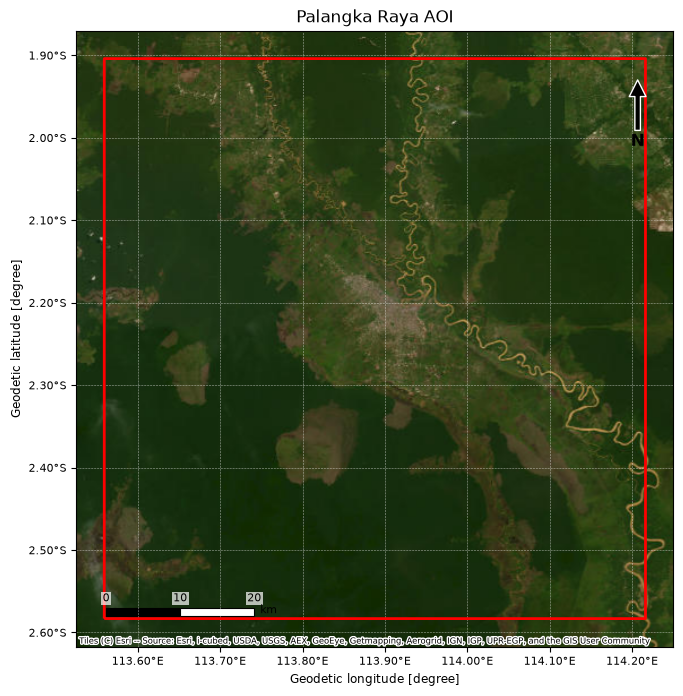

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
aoi.boundary.plot(ax=ax, color="red", linewidth=2)

xmin, ymin, xmax, ymax = aoi.total_bounds
pad = 0.05 * max(xmax - xmin, ymax - ymin)
ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)
cx.add_basemap(ax, crs=aoi.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)

decorate(ax, "Palangka Raya AOI")
plt.show()

## 3. Sentinel-1 composites as RGB

R = VV, G = VH, B = (VV - VH) / (VV + VH). Each channel is stretched between its 2nd and 98th percentile, so the display does not depend on the raster's scale factor.

In [5]:
def stretch(band, valid, low=2, high=98):
    lo, hi = np.percentile(band[valid], [low, high])
    return np.clip((band - lo) / (hi - lo), 0, 1)


def load_s1_rgb(path):
    with rasterio.open(path) as src:
        data = src.read().astype("float32")
        names = [name.lower() for name in src.descriptions]
        bounds = src.bounds
        nodata = src.nodata or 0

    vv = data[names.index("vv")]
    vh = data[names.index("vh")]
    valid = (vv != nodata) & (vh != nodata)
    ratio = np.where(valid, (vv - vh) / np.where(valid, vv + vh, 1), 0)

    rgb = np.dstack([stretch(vv, valid), stretch(vh, valid), stretch(ratio, valid)])
    rgba = np.dstack([rgb, valid.astype("float32")])
    extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
    return rgba, extent


s1 = {date: load_s1_rgb(f"{S1_PREFIX}/palangka_raya_{date}.tif") for date in S1_DATES}

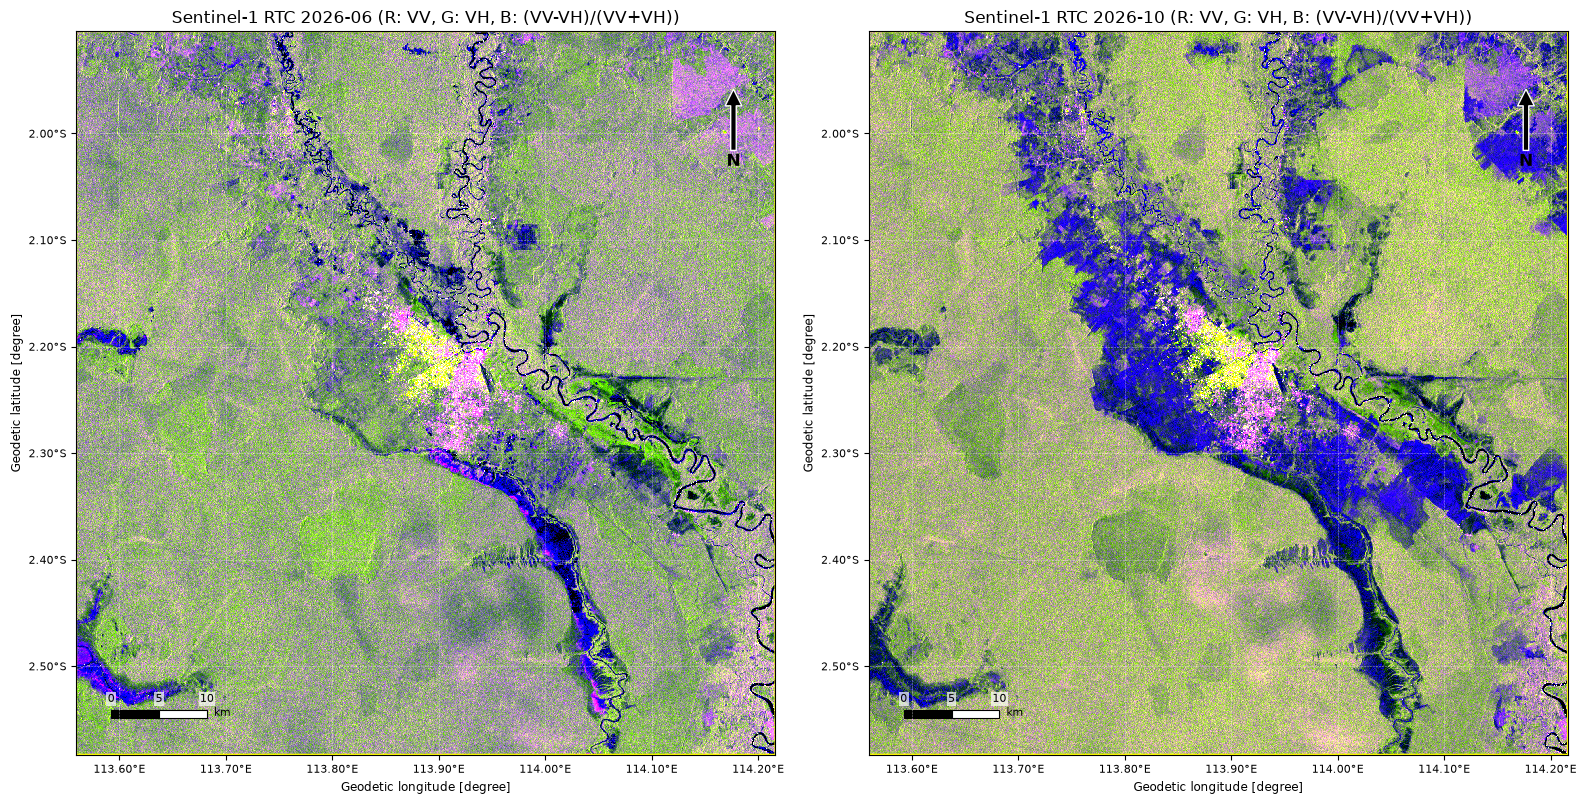

In [6]:
fig, axes = plt.subplots(1, len(s1), figsize=(8 * len(s1), 8))

for ax, (date, (rgba, extent)) in zip(np.atleast_1d(axes), s1.items()):
    ax.imshow(rgba, extent=extent, interpolation="nearest")
    aoi.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    decorate(ax, f"Sentinel-1 RTC {date} (R: VV, G: VH, B: (VV-VH)/(VV+VH))")

plt.tight_layout()
plt.show()